# Activity 7.3.3 Performing ARIMA models in Python

## Scenario
The Baltimore Police Department (BPD), situated in Baltimore, USA, created a data set containing crime records from 1 January 2011 to 18 June 2016. Although the data set is considered preliminary and subject to change, it contains 264,496 rows and 11 columns (BPD, 2024).

For this activity, the data set was adapted to indicate the number of daily crime incidents from 1 January 2011 to 31 December 2015. Therefore, the data set contains 2,143 rows and two columns. You are tasked to analyse the provided data set to forecast future crime predictions. You must also provide a clear and precise rationale for your analysis and findings.


## Objective
In this portfolio activity, you’ll use ARIMA models to forecast crimes.

You will complete the activity in your Notebook, where you’ll:
- load and prepare data
- verify seasonality with ACF
- define and fit five SARIMA models
- forecast next 52 weeks
- fit training set with Auto ARIMA
- identify best model using MSE.



## Assessment criteria
By completing this activity, you will be able to provide evidence that you can:
- Configure and fit multiple SARIMA models with varied (𝑝,𝑑,𝑞)×(𝑃,𝐷,𝑄)orders.

- Run a constrained Auto ARIMA search across a defined grid of nonseasonal and seasonal orders.

- Select the best model using a clear criterion (e.g., lowest AICc).

- Generate out-of-sample forecasts for the test horizon from the selected model, including 95% confidence intervals.

- Evaluate predictive accuracy against the test set using Mean Squared Error (MSE) to assess the better model.



## Activity guidance

1. Run the following commands to load and shape data:

(Note on loading data: This activity continues from Week 6. If you saved the CSV locally in Week 6, adjust the file path to match where you stored it).

```
     crime = pd.read_csv('../python_files/BPD_Part_1_Victim_Based_Crime_Data_dailyIncidents_activity.csv')
     crime['date'] = pd.to_datetime(crime['date'])
     crime.set_index('date', inplace=True)
     crime.asfreq('d')
     crime.sort_index(inplace=True)
     crime['Incidents_imputed_spline'] = crime.Incidents.interpolate(method='spline', order=3)
     crime_weekly = crime.groupby(pd.Grouper(freq='w')).aggregate(np.mean)
     ts = crime_weekly.Incidents_imputed_spline
```


2. Split the data into two parts: A training set 'ts_train', and a test set 'ts_test',
   the latter containing the 52 last observations.
3. Verify (using the ACF) that the seasonal period of ts_train is 52.
4. Define the five following SARIMA models in the form of a python list of order combinations [(p, d, q), (P, D, Q, m)]:


```
   SARIMA(1, 0, 0)(1, 1, 0, 52)
   SARIMA(0, 0, 1)(0, 1, 0, 52)
   SARIMA(0, 0, 0)(0, 1, 1, 52)
   SARIMA(0, 1, 1)(1, 1, 0, 52)
   SARIMA(1, 0, 1)(1, 1, 1, 52)
```


5. Fit the above five models and store the resulting model fits.
6. Create the 52 next model forecasts (with 95% CI's) from all five models corresponding to the 52 test set values.
   Plot separately for each model: ts_train, ts_test, forecast, 95% CI.
7. Calculate the Mean Squared Error for each model between ts_test and forecasted values.
   Which is the preferred model according to the above MSE's?
8. Fit the training set ts_train using the Auto ARIMA function with all default parameters and
   0 <= p <= 2, 0 <= q <= 2, d=0, 0 <= P <= 1, 0 <= Q <= 1, D=1, m=52,
   What is the resulting model?
9. Calculate again the next 52 time steps forecasts corresponding to the test set ts_test, along with a 95% CI.
   Plot ts_train, ts_test, forecast, and 95% CI.
10. Calculate the MSE between ts_test and AutoARIMA forecast. Is it better than the best MSE from the five SARIMA models?

In [1]:
# Numpy versions 2.0 and above are currently incompatible with the latest version of pmdarima. Therefore, I'm downgrading Numpy to a version below 2.0 in this notebook to ensure compatibility.
!pip install "numpy<2.0" pmdarima

In [2]:
# Import the relevant libraries.
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
import statsmodels.graphics.api as smgraphics
from statsmodels.tsa.stattools import adfuller as adf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pmdarima.arima import auto_arima
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error

import warnings

# Suppress specific warnings.
warnings.filterwarnings("ignore", category=FutureWarning)

In [4]:
# Import data set from GitHub repository:
url = '<path-to-dataset>/crime_incidents.csv'

In [5]:
crime = pd.read_csv(url)
crime.head()

,date,incidents
0,01-01-11,185.0
1,01-01-12,176.0
2,01-01-13,157.0
3,01-01-14,139.0
4,01-01-15,157.0


In [6]:
# Step 1: Shape the data into a weekly-average series.
crime['date'] = pd.to_datetime(crime['date'], format='mixed')
crime.set_index('date', inplace=True)
crime.sort_index(inplace=True)
crime = crime.asfreq('d')

# Impute missing values
crime['incidents_imputed_spline'] = crime['incidents'].interpolate(method='spline', order=3)

# Weekly average
crime_weekly = crime.groupby(pd.Grouper(freq='W')).mean()
ts = crime_weekly['incidents_imputed_spline']

print('Index:', type(crime.index).__name__, '| rows:', len(crime))
print('Weekly points:', len(ts))
print('Date range:', ts.index.min(), '->', ts.index.max())
ts.head()

Index: DatetimeIndex | rows: 2143
Weekly points: 307
Date range: 2011-01-02 00:00:00 -> 2016-11-13 00:00:00


,incidents_imputed_spline
date,
2011-01-02,143.500000
2011-01-09,115.857143
2011-01-16,111.541073
2011-01-23,116.428571
2011-01-30,102.680699


In [7]:
# Step 2: Split into training and test sets (test = last 52 weeks).
ts_train = ts[:-52]
ts_test = ts[-52:]

print('Train points:', len(ts_train))
print('Test points:', len(ts_test))
print('Train range:', ts_train.index.min(), '->', ts_train.index.max())
print('Test range: ', ts_test.index.min(), '->', ts_test.index.max())

Train points: 255
Test points: 52
Train range: 2011-01-02 00:00:00 -> 2015-11-15 00:00:00
Test range:  2015-11-22 00:00:00 -> 2016-11-13 00:00:00


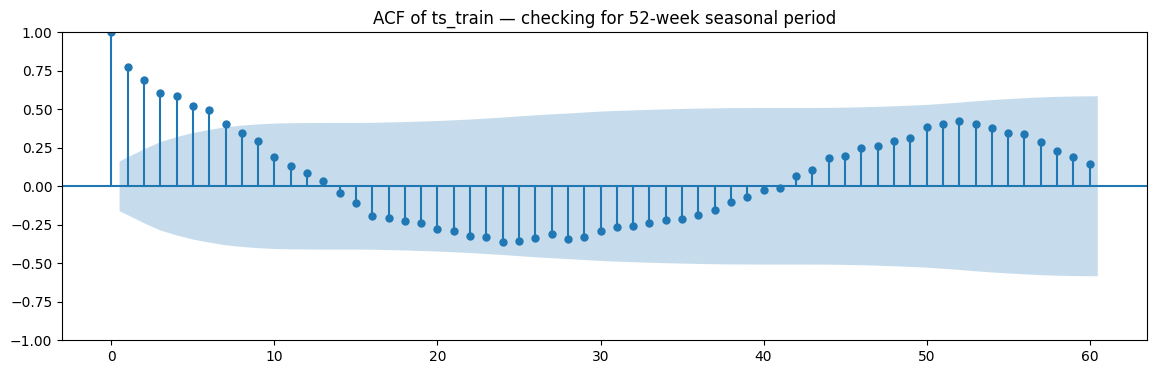

In [8]:
# Step 3: Verify seasonality — ACF of ts_train should show a peak around lag 52.
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(ts_train, lags=60, alpha=0.01, ax=ax)
ax.set_title('ACF of ts_train — checking for 52-week seasonal period')
plt.show()

The ACF confirms the 52 weeks seasonality.
- Lags 1-13 are positive above the band.
- Lags 14-40 are negative therefore a negative correlation.
- Lags 45-52 are positive again to capture a the full year picture.

The ACF shows a clear seasonal oscillation: strong positive autocorrelation at short lags decays and turns negative around the half-year mark (~lag 26), then rises back to a positive peak at lag 52 (ACF = 0.425). This maximum at exactly one-year separation confirms an annual, 52-week seasonal period in the training data, justifying the seasonal term m=52 in the SARIMA models that follow.

In [9]:
from statsmodels.tsa.stattools import acf
acf_vals = acf(ts_train, nlags=60)
peak_lag = acf_vals[40:].argmax() + 40   # search the seasonal region (lag 40+)
print('Peak lag in seasonal region:', peak_lag, '| value:', round(acf_vals[peak_lag], 3))

Peak lag in seasonal region: 52 | value: 0.425


In [10]:
# Step 4: Define the five SARIMA models as [(p,d,q), (P,D,Q,m)] order combinations.
sarima_orders = [
    [(1, 0, 0), (1, 1, 0, 52)],
    [(0, 0, 1), (0, 1, 0, 52)],
    [(0, 0, 0), (0, 1, 1, 52)],
    [(0, 1, 1), (1, 1, 0, 52)],
    [(1, 0, 1), (1, 1, 1, 52)],
]

for i, (order, seasonal_order) in enumerate(sarima_orders, 1):
    print(f"Model {i}: SARIMA{order}{seasonal_order}")

Model 1: SARIMA(1, 0, 0)(1, 1, 0, 52)
Model 2: SARIMA(0, 0, 1)(0, 1, 0, 52)
Model 3: SARIMA(0, 0, 0)(0, 1, 1, 52)
Model 4: SARIMA(0, 1, 1)(1, 1, 0, 52)
Model 5: SARIMA(1, 0, 1)(1, 1, 1, 52)


In [11]:
# Step 5: Fit the five SARIMA models and store the resulting fits.
sarima_fits = []

for i, (order, seasonal_order) in enumerate(sarima_orders, 1):
    print(f"Fitting Model {i}: SARIMA{order}{seasonal_order} ...")
    model = SARIMAX(ts_train, order=order, seasonal_order=seasonal_order)
    fit = model.fit(disp=False)
    sarima_fits.append(fit)
    print(f"   done — AIC: {fit.aic:.2f}")

print("\nAll five models fitted.")

Fitting Model 1: SARIMA(1, 0, 0)(1, 1, 0, 52) ...
   done — AIC: 1547.79
Fitting Model 2: SARIMA(0, 0, 1)(0, 1, 0, 52) ...
   done — AIC: 1585.61
Fitting Model 3: SARIMA(0, 0, 0)(0, 1, 1, 52) ...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


   done — AIC: 1596.56
Fitting Model 4: SARIMA(0, 1, 1)(1, 1, 0, 52) ...
   done — AIC: 1539.14
Fitting Model 5: SARIMA(1, 0, 1)(1, 1, 1, 52) ...


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:1009: UserWarning: Non-invertible starting seasonal moving average Using zeros as starting parameters.
  warn('Non-invertible starting seasonal moving average'


   done — AIC: 1528.65

All five models fitted.


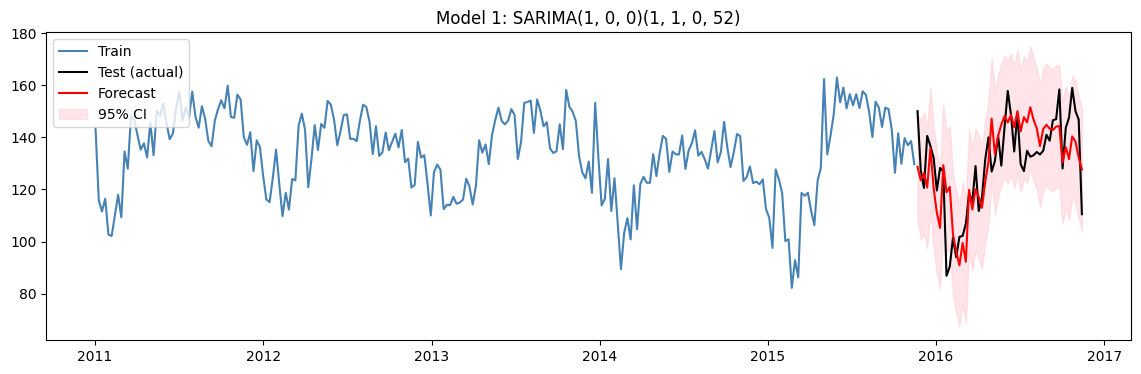

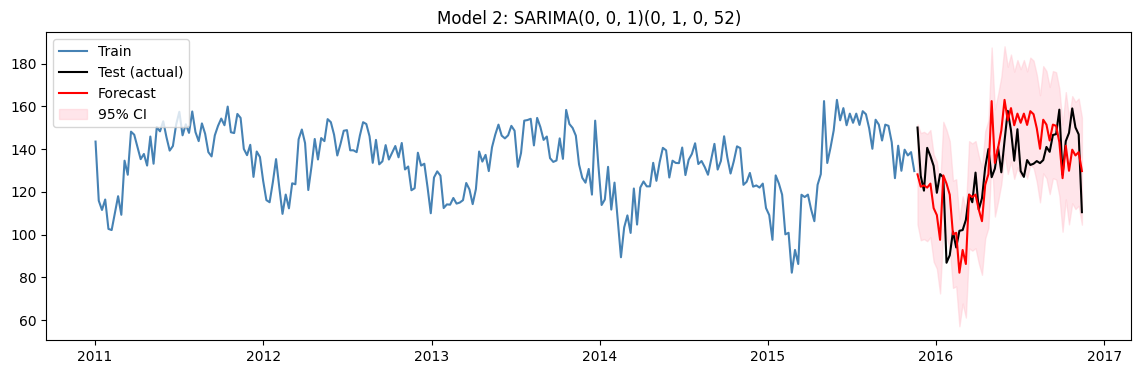

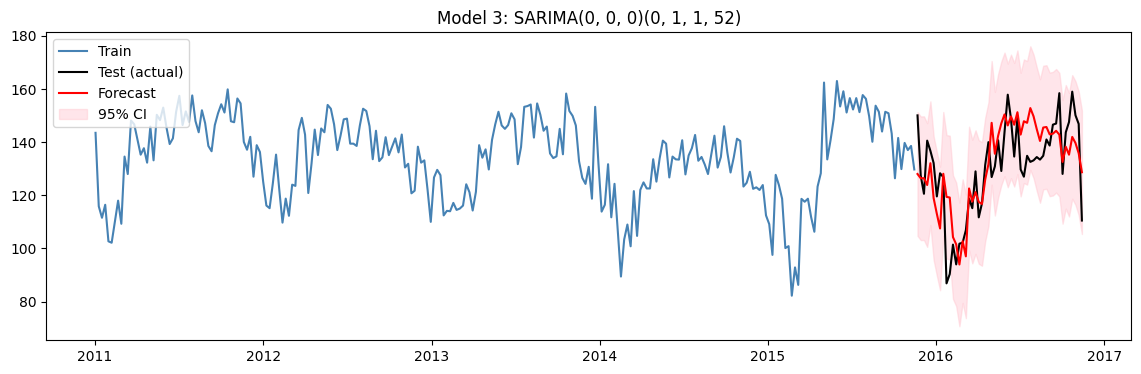

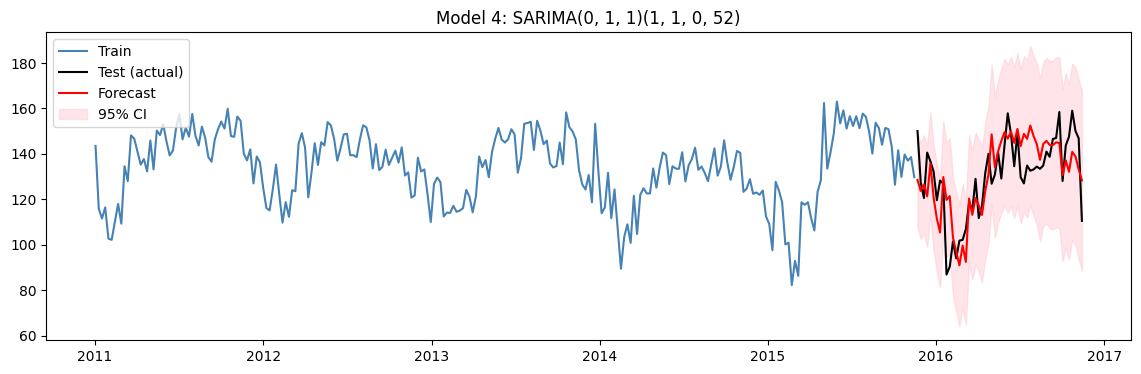

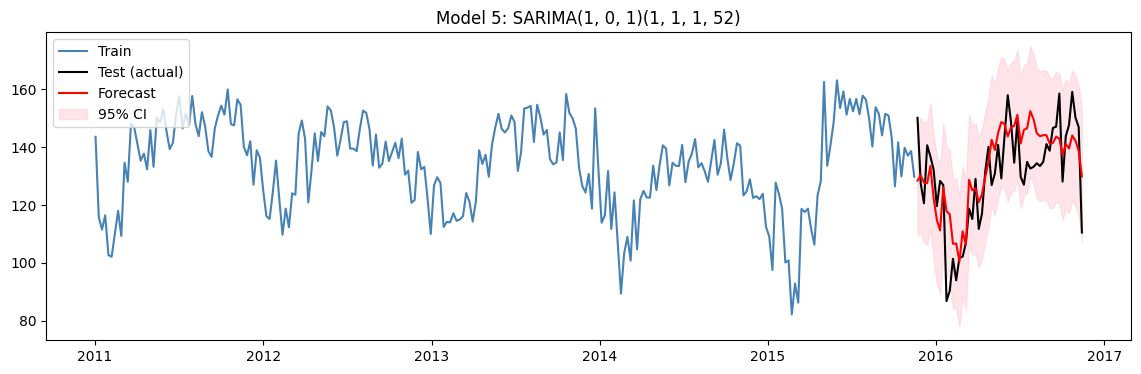

In [12]:
# Step 6: Forecast 52 weeks ahead (with 95% CI) from each model; plot separately.
sarima_forecasts = []

for i, fit in enumerate(sarima_fits, 1):
    # Forecast the next 52 steps
    fc = fit.get_forecast(steps=52)
    mean_fc = fc.predicted_mean
    ci = fc.conf_int(alpha=0.05)   # 95% CI
    sarima_forecasts.append((mean_fc, ci))

    # Plot: train, test, forecast, CI
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(ts_train.index, ts_train, label='Train', color='steelblue')
    ax.plot(ts_test.index, ts_test, label='Test (actual)', color='black')
    ax.plot(mean_fc.index, mean_fc, label='Forecast', color='red')
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1],
                    color='pink', alpha=0.4, label='95% CI')
    order, seasonal_order = sarima_orders[i-1]
    ax.set_title(f'Model {i}: SARIMA{order}{seasonal_order}')
    ax.legend(loc='upper left')
    plt.show()

All five models capture the seasonal shape — the winter dip in early 2016 and the recovery through the year. The red lines all follow the general up-down of the black actuals. The actual values printed on step 5 is easier to read and spot the actual values.

In [13]:
# Step 7: Mean Squared Error between ts_test and each model's forecast.
mse_results = []

for i, (mean_fc, ci) in enumerate(sarima_forecasts, 1):
    mse = mean_squared_error(ts_test, mean_fc)
    order, seasonal_order = sarima_orders[i-1]
    mse_results.append((i, order, seasonal_order, mse))
    print(f"Model {i}: SARIMA{order}{seasonal_order}  ->  MSE = {mse:.2f}")

# Identify the preferred (lowest-MSE) model
best = min(mse_results, key=lambda x: x[3])
print(f"\nPreferred model (lowest MSE): Model {best[0]} "
      f"SARIMA{best[1]}{best[2]} with MSE = {best[3]:.2f}")

Model 1: SARIMA(1, 0, 0)(1, 1, 0, 52)  ->  MSE = 156.78
Model 2: SARIMA(0, 0, 1)(0, 1, 0, 52)  ->  MSE = 262.48
Model 3: SARIMA(0, 0, 0)(0, 1, 1, 52)  ->  MSE = 153.14
Model 4: SARIMA(0, 1, 1)(1, 1, 0, 52)  ->  MSE = 161.83
Model 5: SARIMA(1, 0, 1)(1, 1, 1, 52)  ->  MSE = 139.98

Preferred model (lowest MSE): Model 5 SARIMA(1, 0, 1)(1, 1, 1, 52) with MSE = 139.98


Preferred model is Model 5, SARIMA(1,0,1)(1,1,1,52), MSE = 139.98. The model that fit the training data best also forecast the unseen test year.

Model 3 is the counterexample. It had the worst AIC (1596.56) but the second-best MSE (153.14). So the model that fit the training data poorest still forecast well.

In [14]:
# Step 8: Auto ARIMA on ts_train with the constrained grid from the brief.
auto_model = auto_arima(
    ts_train,
    start_p=0, max_p=2,
    start_q=0, max_q=2,
    d=0,
    start_P=0, max_P=1,
    start_Q=0, max_Q=1,
    D=1,
    m=52,
    seasonal=True,
    trace=True,
    error_action='ignore',
    suppress_warnings=True,
    stepwise=True
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,1,0)[52] intercept   : AIC=1621.326, Time=0.33 sec
 ARIMA(1,0,0)(1,1,0)[52] intercept   : AIC=1544.481, Time=12.59 sec
 ARIMA(0,0,1)(0,1,1)[52] intercept   : AIC=inf, Time=14.28 sec
 ARIMA(0,0,0)(0,1,0)[52]             : AIC=1623.752, Time=0.35 sec
 ARIMA(1,0,0)(0,1,0)[52] intercept   : AIC=1572.764, Time=1.66 sec
 ARIMA(1,0,0)(1,1,1)[52] intercept   : AIC=inf, Time=43.51 sec
 ARIMA(1,0,0)(0,1,1)[52] intercept   : AIC=inf, Time=14.04 sec
 ARIMA(0,0,0)(1,1,0)[52] intercept   : AIC=1582.935, Time=10.43 sec
 ARIMA(2,0,0)(1,1,0)[52] intercept   : AIC=1543.603, Time=16.70 sec
 ARIMA(2,0,0)(0,1,0)[52] intercept   : AIC=1572.546, Time=4.85 sec
 ARIMA(2,0,0)(1,1,1)[52] intercept   : AIC=inf, Time=49.04 sec
 ARIMA(2,0,0)(0,1,1)[52] intercept   : AIC=inf, Time=16.08 sec
 ARIMA(2,0,1)(1,1,0)[52] intercept   : AIC=1539.281, Time=35.19 sec
 ARIMA(2,0,1)(0,1,0)[52] intercept   : AIC=1562.772, Time=5.38 sec
 ARIMA(2,0,1)(1,1,1)[52] intercept 

The constrained Auto ARIMA search selected SARIMA(1,0,2)(1,1,0)₅₂ (AIC = 1538.32). Its key terms are significant and residual diagnostics are healthy (no autocorrelation, stable variance), though residuals are mildly non-normal. This differs from all five prescribed models and has a higher AIC than the manual Model 5 (1528.65) — because every seasonal-MA candidate failed to fit, the search couldn't reach Model 5's structure. This suggests automated selection doesn't guarantee a better model than manual specification; Step 10 tests this via MSE.

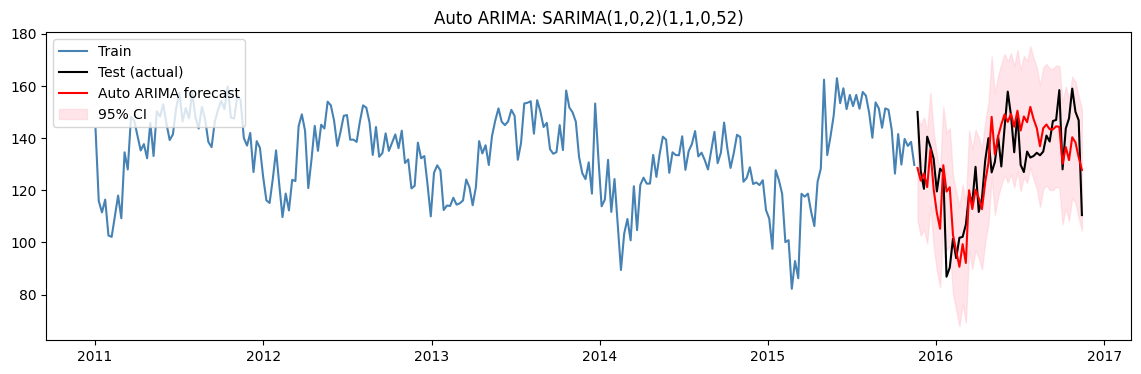

In [15]:
# Step 9: Forecast 52 weeks ahead from the Auto ARIMA model, with 95% CI.
auto_fc, auto_ci = auto_model.predict(n_periods=52, return_conf_int=True, alpha=0.05)

# pmdarima returns a plain array; align it to the test set's dates for plotting
auto_fc = pd.Series(auto_fc, index=ts_test.index)
auto_ci_lower = pd.Series(auto_ci[:, 0], index=ts_test.index)
auto_ci_upper = pd.Series(auto_ci[:, 1], index=ts_test.index)

# Plot: train, test, forecast, 95% CI
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(ts_train.index, ts_train, label='Train', color='steelblue')
ax.plot(ts_test.index, ts_test, label='Test (actual)', color='black')
ax.plot(auto_fc.index, auto_fc, label='Auto ARIMA forecast', color='red')
ax.fill_between(auto_ci_lower.index, auto_ci_lower, auto_ci_upper,
                color='pink', alpha=0.4, label='95% CI')
ax.set_title('Auto ARIMA: SARIMA(1,0,2)(1,1,0,52)')
ax.legend(loc='upper left')
plt.show()

In [16]:
# Step 10: MSE of the Auto ARIMA forecast vs the test set, compared to the best SARIMA.
auto_mse = mean_squared_error(ts_test, auto_fc)
print(f"Auto ARIMA SARIMA(1,0,2)(1,1,0,52)  ->  MSE = {auto_mse:.2f}")

# Recall the best manual model from Step 7
print(f"Best manual model (Model 5) SARIMA(1,0,1)(1,1,1,52)  ->  MSE = 139.98")

if auto_mse < 139.98:
    print(f"\nAuto ARIMA is BETTER (lower MSE) by {139.98 - auto_mse:.2f}")
else:
    print(f"\nModel 5 is BETTER (lower MSE) by {auto_mse - 139.98:.2f}")

Auto ARIMA SARIMA(1,0,2)(1,1,0,52)  ->  MSE = 160.46
Best manual model (Model 5) SARIMA(1,0,1)(1,1,1,52)  ->  MSE = 139.98

Model 5 is BETTER (lower MSE) by 20.48


Auto ARIMA's MSE (160.46) is worse than Model 5's (139.98) — Model 5 wins by 20.48.



### Reflection

This analysis demonstrates that Baltimore's weekly crime incidents follow a strong, dependable annual cycle (confirmed by a seasonal ACF peak at lag 52), with a winter low and a warmer-season rise that repeats year to year. Operationally, this predictability is valuable: it means the department can anticipate seasonal demand up to a year in advance and plan staffing, overtime, staff holiday, patrol resources proactively rather than reactively.

Of the models tested, the manually-specified SARIMA(1,0,1)(1,1,1,52) produced the most accurate 52-week forecast (MSE = 139.98, ≈ ±11.8 incidents per week), outperforming both the other four models and the automated Auto ARIMA selection (MSE = 160.46).
The 95% confidence intervals along with the forecast allow planners to prepare not only for the expected weekly caseload but also for plausible upper-bound demand — supporting contingency budgeting.

These results should be treated as a planning aid rather than a precise prediction. The forecasts assume historical patterns persist, so any structural change — policy shifts, demographic change, or unusual events — could reduce accuracy. The dataset is also described as preliminary and extends only into 2016, so the model should be monitored and periodically re-fitted as new data becomes available. Used this way — as decision support that quantifies both the expected pattern and its uncertainty — time-series forecasting offers Baltimore PD a practical tool for evidence-based seasonal resource planning.